<a href="https://colab.research.google.com/github/Danlowst/Desafio2_Estatistica_Python/blob/main/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Célula 01 · Importações

In [1]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

### Célula 02 · Carregar os arquivos CSV

In [2]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "atracoes"   # ex.: "livros"
NOME_TABELA_FATO = "ingressos_vendidos"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Mounted at /content/drive
Selecione os arquivos CSV (atracoes e ingressos_vendidos). Pode escolher os dois de uma vez:


Saving atracoes.csv to atracoes.csv
Saving ingressos_vendidos.csv to ingressos_vendidos.csv
atracoes.csv -> atracoes.csv
ingressos_vendidos.csv -> ingressos_vendidos.csv
atracoes -> 10100 linhas
ingressos_vendidos -> 55000 linhas


### Célula 03 · Conhecendo a tabela dimensão

In [3]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10100 linhas e 7 colunas (variáveis)


,atracao_id,nome_artista,genero_musical,edicao_festival,dia_apresentacao,palco,horario_inicio
0,1,Banda Moura,sertanejo,Festival Illo 2025,2025-01-23,eletronico,20:45
1,2,Coletivo Casa Grande,rap,Festival Nobis 2026,2026-04-20,secundario,13:45
2,3,Banda da Rosa,eletronica,Festival Voluptate 2023,2023-05-23,secundario,12:00
3,4,Banda Farias,rap,Festival Iusto 2026,2026-10-11,principal,16:00
4,5,Rodrigues,reggae,Festival Aperiam 2023,2023-04-06,eletronico,12:30


### Célula 04 · Conhecendo a tabela fato

In [4]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 7 colunas (variáveis)


,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix


### Célula 05 · Tipos de colunas

In [9]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato["data_hora_venda"] = pd.to_datetime(df_fato["data_hora_venda"])
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   venda_id         55000 non-null  int64         
 1   atracao_id       55000 non-null  int64         
 2   tipo_ingresso    55000 non-null  object        
 3   canal_venda      55000 non-null  object        
 4   data_hora_venda  55000 non-null  datetime64[ns]
 5   valor            55000 non-null  float64       
 6   forma_pagamento  55000 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(3)
memory usage: 2.9+ MB


### Célula 06 · Valores ausentes

In [6]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
venda_id           0
atracao_id         0
tipo_ingresso      0
canal_venda        0
data_hora_venda    0
valor              0
forma_pagamento    0
dtype: int64


### Célula 07 · Linhas duplicadas


In [7]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


### Célula 08 · Chave estrangeira


In [8]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "atracao_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "atracao_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


**Leitura da conferência**

- 55.000 linhas e nenhuma linha duplicada.
- A chave estrangeira (atracao_id) bate com a dimensão (atracao_id).
- Não há valores ausentes.
- Em todas as colunas, não há valores ausentes.

### Célula 09 · Checar a coluna numérica


In [10]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "valor"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


### Célula 10 · Medidas estatísticas

In [11]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,469.54
Mediana,290.00
Moda,202.98
Desvio padrão,455.12
Variância,207135.74
Mínimo,80.55
Máximo,2975.31
Amplitude,2894.76


Média - mediana: 179.54


- **A média de valor é 469,54**: Que o valor médio pago pelo ingresso é R$469,54

- **A mediana de valor é 290,00**. Que a média pode enganar, pois cerca de metade dos ingressos vendidos tem o valor de até 290,00

- **O desvio padrão de valor é 455.12**. Mostra que os dados estão bem distântes da média, ou seja, indica que são muito variados.

- **Decisão final:** Manter as categorias de ingressos separadas, tendo como base o valor da mediana para o publico geral, pois os valores altos distorcem a média.

### Célula 11 · Juntar a fato com a dimensão

In [12]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 55000 | depois da junção: 55000


### Célula 12 · Comparar grupos por uma coluna da fato


In [13]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "tipo_ingresso"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
tipo_ingresso,,,,
camarote,3797,1782.10,1771.68,471.86
vip,9843,825.69,812.64,207.04
pista_premium,10844,415.83,410.02,103.58
pista,30516,210.43,207.84,67.43


**Leitura por tipo de ingresso**

- O grupo do camarote é o que tem a maior média e a maior mediana.
- O grupo com valores mais espalhados também é o camarote.
- Os grupos não tem médias semelhantes, o que indica que as categorias separam perfis muito distintos de compradores.

### Célula 13 · Comparar grupos por uma coluna da dimensão


In [14]:
COLUNA_GRUPO = "palco"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
palco,,,,
eletronico,6730,470.89,290.90,452.44
secundario,16737,470.25,291.21,455.42
principal,28671,469.17,289.55,455.55
acustico,2862,465.84,284.97,455.60


**Leitura por tipo de palco**

- O grupo com a maior média é o eletronico, porém, a maior mediana é o do palco secundario, indicando que possivelmente há outliers puxando o valor da média para cima.
- O grupo com os valores mais espalhados é o acustico, porém, a diferença para os outros é minima, indicando que a dispersão dos dados é bem semelhante em todos os grupos.
- Indica que o palco influencia pouco com relação ao valor pago.

### Célula 14 · Regra do IQR

In [15]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -347.47 a 1104.52
Outliers: 4653 de 55000 valores
Maiores valores: [2975.31, 2973.81, 2957.95, 2944.94, 2943.81]
Menores valores: [80.55, 81.14, 81.34, 81.77, 81.92]


### Célula 15 · Medidas com e sem os candidatos a outlier

In [16]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,469.54,357.40
Mediana,290.00,273.09
Desvio padrão,455.12,238.74


**Leitura e decisão registrada**

- Marcou 4653 de 55000 valores, Limites: -347.47 a 1104.52, Sem os outliers, a média cai para 357.40, a mediana cai para 273.09 e o desvio padrão cai para 238.74
- **Decisão:** Manter, pois se tratando de venda, não são erros de digitação, são compras reais de alto valor, como os ingressos camarote.
- **Valores ausentes:** Não há valores ausentes

### Célula 16 · Assimetria (skew)

In [17]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 2.36


### Célula 17 · Percentis

In [18]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     139.1380
0.25     197.0275
0.50     290.0050
0.75     560.0225
0.90    1028.7440
Name: valor, dtype: float64


### Célula 18 · Quantidade de valores por faixa

In [20]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())
display((pd.cut(serie_numerica, bins=5).value_counts(normalize=True).sort_index() * 100).round(2))


,count
valor,
"(77.655, 659.502]",43778
"(659.502, 1238.454]",7740
"(1238.454, 1817.406]",1717
"(1817.406, 2396.358]",1331
"(2396.358, 2975.31]",434


,proportion
valor,
"(77.655, 659.502]",79.60
"(659.502, 1238.454]",14.07
"(1238.454, 1817.406]",3.12
"(1817.406, 2396.358]",2.42
"(2396.358, 2975.31]",0.79


**Leitura da distribuição**

- valor da assimetria = 2.36 indicando uma calda para os valores altos.
- percentis: até 75% = 560.0225 e 90% = 1028.7440
- primeira faixa = 43778 e a partir dai, as mais altas ficam 1717, 1331 e 434, da menor para a maior.
- Em palavras: a maioria dos valores fica entre 77.65 e 659.50, cerca de 43778 ingresso e poucos passam de 1238.45, cerca de 3482 ingressos.

## Recomendação

**Pergunta de negócio:** O preço dos ingressos é consistente entre as vendas ou varia de acordo com o tipo de ingresso?

**Evidência 1:** A diferença da média = 469.54 para a mediana =	290.00, demonstra que há alguns valores altos que estão aumentando a média e, vendo a mediana, é possivel concluir que pelo menos 50% dos compradores gastam cerca de 290.00 reais.

**Evidência 2:** Quando os valores são separados por faixas de preço, é possivel ver que cerca de 80% dos compradores gastaram até 659.50 reais e apenas 6% dos valores estão acima de 1238.45.

**Evidência 3:** Quando se olha a média, a mediana e o desvio padrão por tipo de ingresso, concluí-se que as vendas se mantem consistentes por grupo, ou seja, eles são bastantes distintos entre si.

**Recomendação em uma frase:** Baseie o preços e vendas na mediana (290.00) pois abrange a maioria do público que opta por ingressos de baixo valor, sendo apenas uma pequena parte do público opta por ingressos de valores mais elevados.

**Limites da análise:** Os dados são ficticios. Os outliers foram mantidos por se tratarem de vendas de alto valor, e não houve valores ausentes.

### Célula 19 · Histograma


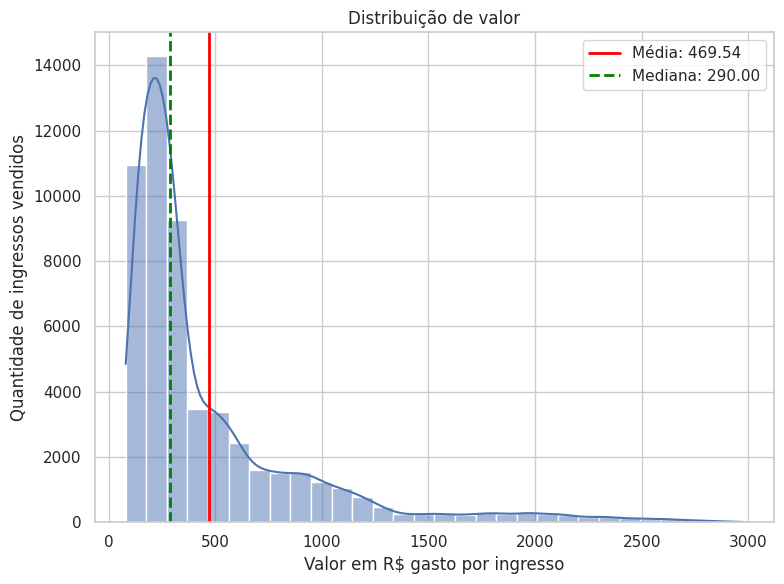

In [23]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Valor em R$ gasto por ingresso")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("Quantidade de ingressos vendidos")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

O gráfico demostra que há uma assimetria à direita, mostrando que a maior parte das vendas está concentrada nos ingressos de valor mais baixo enquanto a calda se estica para os mais altos.
É possivel entender visualmente que o valor que mais se aproxima daquele gasto pela maior quantidade de pessoas é a mediana (290.00).

### Célula 20 · Boxplot

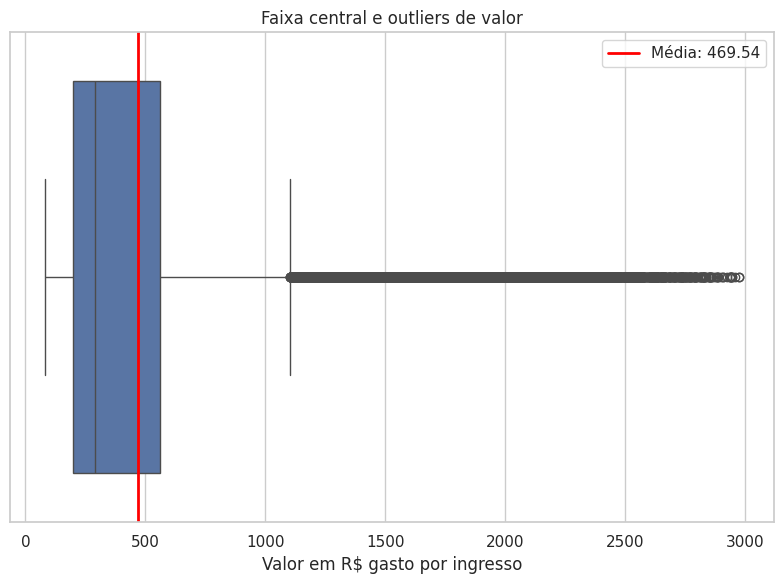

In [25]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Valor em R$ gasto por ingresso")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

O boxplot mostra os outliers que há dentro dos dados, porém, eles são mantidos pois se tratam de valores reais maiores que 1104.52. Eles demonstram que há vendas de alto valor, porém, que são bem diferentes dos outros valores restantes, fazendo com que a média geral suba.